# Voyage Analytics — Flight Price Regression
    **Project type:** Regression  
    **Contribution:** Individual  
    **Author:** techysuman27 (replace with your preferred submission name if needed)

    # Project Summary
    Estimate historical flight prices from route, cabin, agency, duration, distance and date. Predictions are dataset-unit estimates, not live fares.

    This notebook provides the assessed modeling narrative. The shared package implements repeatable training and preprocessing used by Flask and Airflow as well. MLflow captures the experiment; Docker, Kubernetes and Jenkins belong to the accompanying repository. Measured outputs below come from this dataset and must not be described as real-world travel-market performance.

    # GitHub Link
    https://github.com/techysuman27/MLOps-Travel-App

    # Problem Statement
    Estimate historical flight prices from route, cabin, agency, duration, distance and date. Predictions are dataset-unit estimates, not live fares.

    # General Guidelines
    Follow the supplied template's eight main sections. This original notebook contains fifteen training-only visualizations, with reasons, measured observations and business implications. The test partition is reserved for final evaluation. Run all cells in order. The initial bootstrap may require network access in Colab.

In [1]:
import os, sys, subprocess
from pathlib import Path
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    root = Path('/content/MLOps-Travel-App')
    if not root.exists():
        subprocess.run(['git', 'clone', 'https://github.com/techysuman27/MLOps-Travel-App.git', str(root)], check=True)
    os.chdir(root)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '.'], check=True)
else:
    root = Path.cwd()
    if root.name == 'notebooks': root = root.parent
    os.chdir(root)
    sys.path.insert(0, str(root / 'src'))
if not Path('data/raw/flights.csv').exists():
    subprocess.run([sys.executable, 'scripts/download_data.py'], check=True)
TASK = 'flights'
print('Repository:', root)

Repository: C:\Users\dataw\OneDrive\Desktop\Almabetter Master Project


## 1. Know Your Data
### Import Libraries and Dataset Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
from sklearn.model_selection import train_test_split
from voyage.data import load_data, chronological_split, sha256
from voyage.exploration import draw_chart
from voyage.training import run_training
from voyage.artifacts import load_bundle, promote
frames = load_data('data/raw')
df = frames['users' if TASK == 'classification' else TASK]
print('Rows and columns:', df.shape)
display(df.drop(columns=['name'], errors='ignore').head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()}))
print('Exact duplicates:', df.duplicated().sum())

Rows and columns: (271888, 10)


,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,2019-09-26
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,2019-09-30
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,2019-10-03
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,2019-10-04
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,2019-10-10


,dtype,missing,unique
travelCode,int64,0,135944
userCode,int64,0,1335
from,str,0,9
to,str,0,9
flightType,str,0,3
price,float64,0,490
time,float64,0,33
distance,float64,0,35
agency,str,0,3
date,datetime64[us],0,999


Exact duplicates: 0


### What did we learn about the dataset?
    Validation checks the required columns, numeric values, dates and user references. No empty fields or exact duplicate rows were found in the initial source audit. This does not establish representativeness or real-world validity. A travel/user pair has two flight legs; hotel totals must not be summed after an unrestricted flight join.

## 2. Understanding Your Variables

In [3]:
descriptions = {
    'travelCode': 'Trip identifier; grouping and linkage only', 'userCode': 'User reference; history and linkage only',
    'code': 'User identifier; excluded from classification features', 'from': 'Recorded origin', 'to': 'Recorded destination',
    'flightType': 'Recorded cabin category', 'price': 'Flight price or hotel nightly price, according to table',
    'time': 'Recorded flight duration', 'distance': 'Recorded flight distance; units unverified',
    'agency': 'Recorded agency', 'date': 'Recorded travel/booking date', 'name': 'User name or hotel name, according to table',
    'place': 'Hotel destination', 'days': 'Stay duration', 'total': 'Nightly price times stay duration',
    'company': 'Associated company', 'gender': 'Source label: male, female, none; none is undocumented', 'age': 'Recorded user age'
}
display(pd.DataFrame({'variable': df.columns, 'meaning': [descriptions[c] for c in df.columns]}))

,variable,meaning
0,travelCode,Trip identifier; grouping and linkage only
1,userCode,User reference; history and linkage only
2,from,Recorded origin
3,to,Recorded destination
4,flightType,Recorded cabin category
5,price,"Flight price or hotel nightly price, according..."
6,time,Recorded flight duration
7,distance,Recorded flight distance; units unverified
8,agency,Recorded agency
9,date,Recorded travel/booking date


## 3. Data Wrangling

In [4]:
if TASK == 'classification':
    train, rest = train_test_split(df, test_size=.30, stratify=df.gender, random_state=42)
    valid, test = train_test_split(rest, test_size=.5, stratify=rest.gender, random_state=42)
    split = {'train': len(train), 'validation': len(valid), 'test': len(test)}
    assert set(train.code).isdisjoint(test.code)
else:
    train, valid, test, split = chronological_split(df, group_trips=TASK == 'flights')
    assert train.date.max() < valid.date.min() < test.date.min()
display(split)
eda = train.copy()

{'validation_start': '2021-07-01',
 'test_start': '2022-02-17',
 'train_rows': 189782,
 'validation_rows': 40918,
 'test_rows': 41188,
 'purged_rows': 0}

### Manipulations and reasoning
    Source dates are parsed explicitly. Numerical contract violations stop execution instead of being silently filled. There is no need to impute this complete source snapshot. Exploration below uses only the training partition. Flight trips crossing time boundaries are purged. For users, stratification preserves label representation while keeping each user in one partition. For hotels, future interactions remain held out and repeat bookings stay eligible.

## 4. Data Visualization, Storytelling and Experimenting with Charts

### Chart 1
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

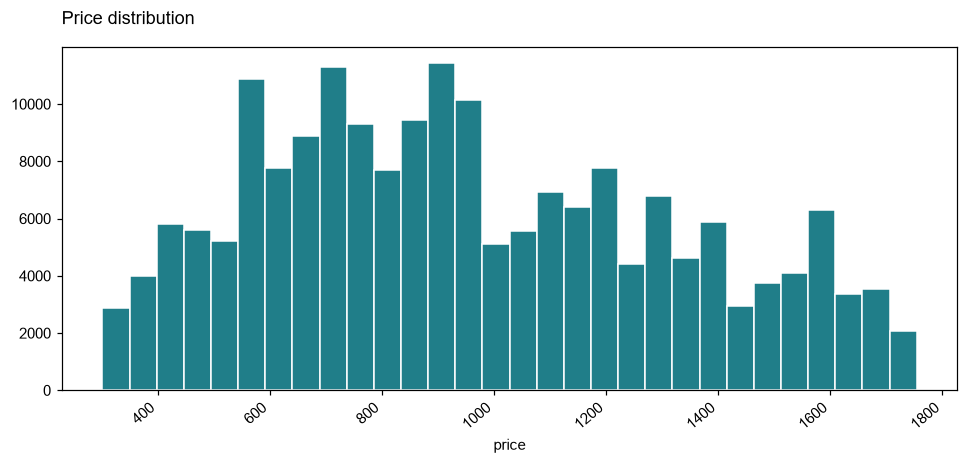

Observed insight: price: median=899.60; 10th–90th percentile=506.56–1515.79.


In [5]:
figure, observed_insight = draw_chart(TASK, 0, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 2
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

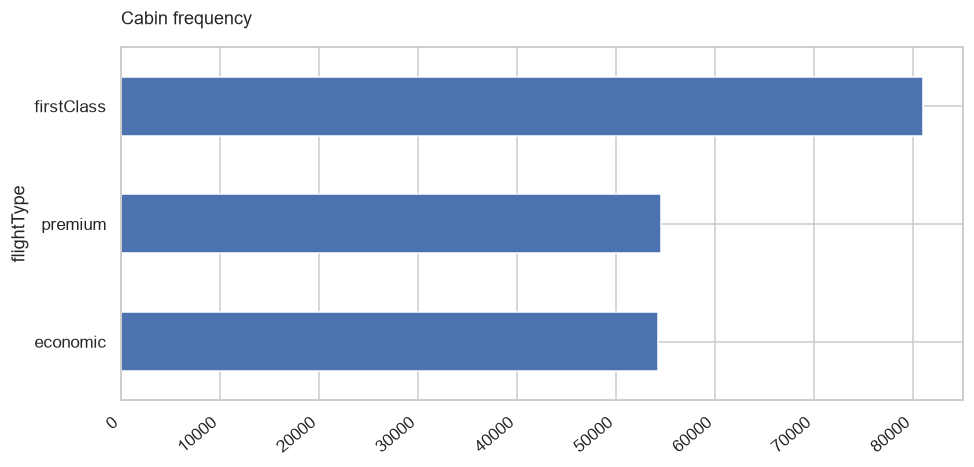

Observed insight: firstClass has the largest count (81,016) in the training partition.


In [6]:
figure, observed_insight = draw_chart(TASK, 1, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 3
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

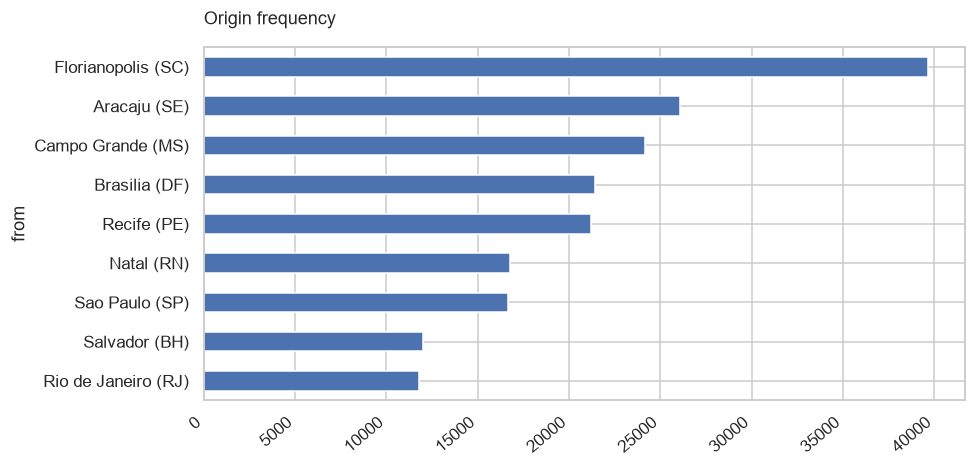

Observed insight: Florianopolis (SC) has the largest count (39,683) in the training partition.


In [7]:
figure, observed_insight = draw_chart(TASK, 2, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 4
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

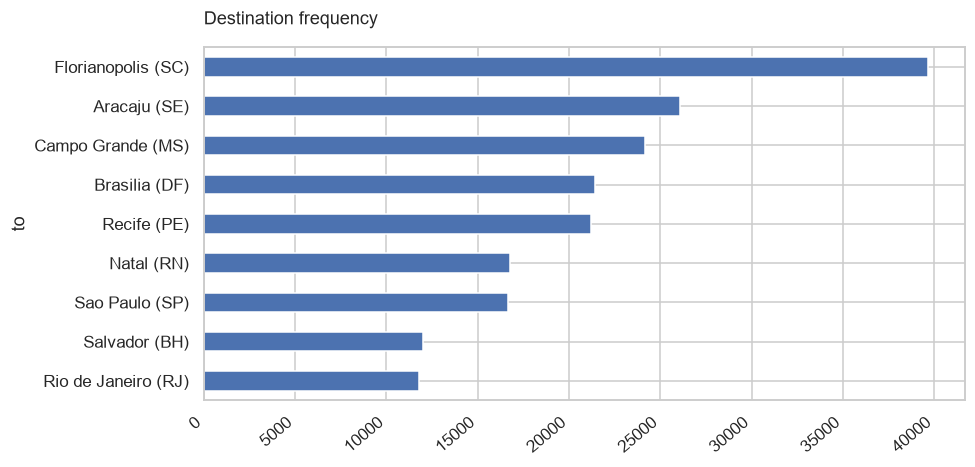

Observed insight: Florianopolis (SC) has the largest count (39,683) in the training partition.


In [8]:
figure, observed_insight = draw_chart(TASK, 3, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 5
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

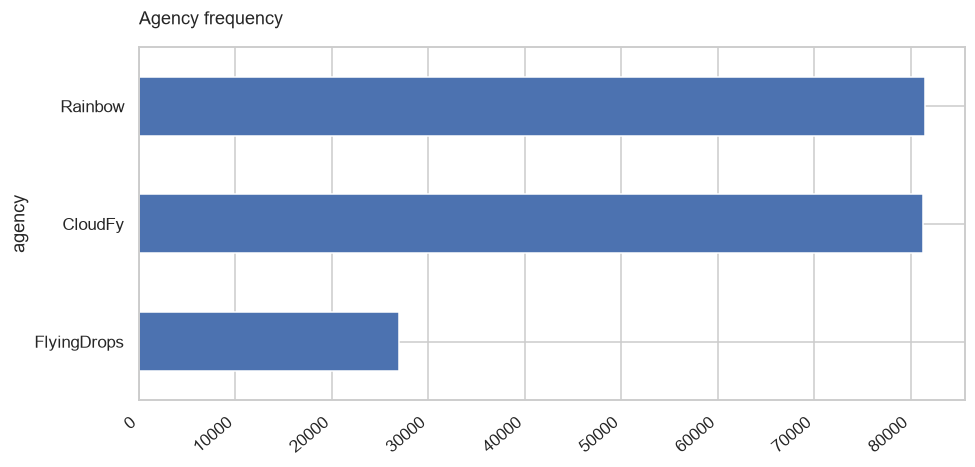

Observed insight: Rainbow has the largest count (81,514) in the training partition.


In [9]:
figure, observed_insight = draw_chart(TASK, 4, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 6
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

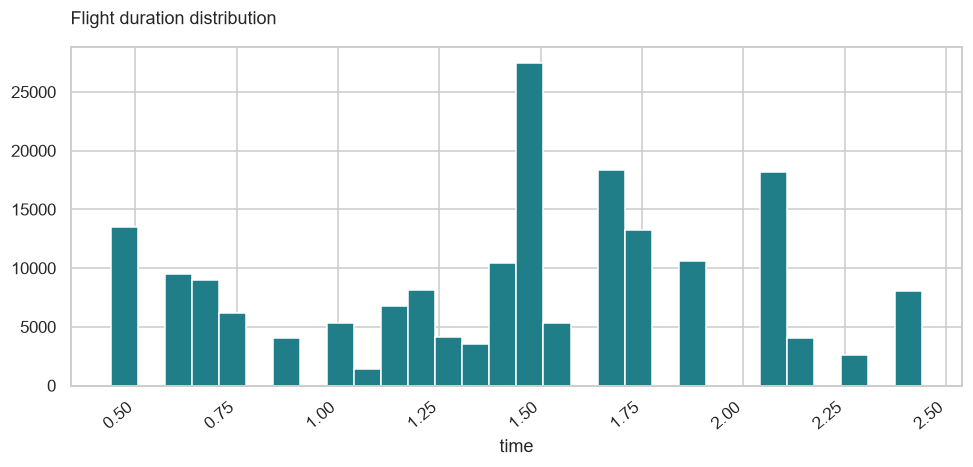

Observed insight: time: median=1.46; 10th–90th percentile=0.63–2.10.


In [10]:
figure, observed_insight = draw_chart(TASK, 5, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 7
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

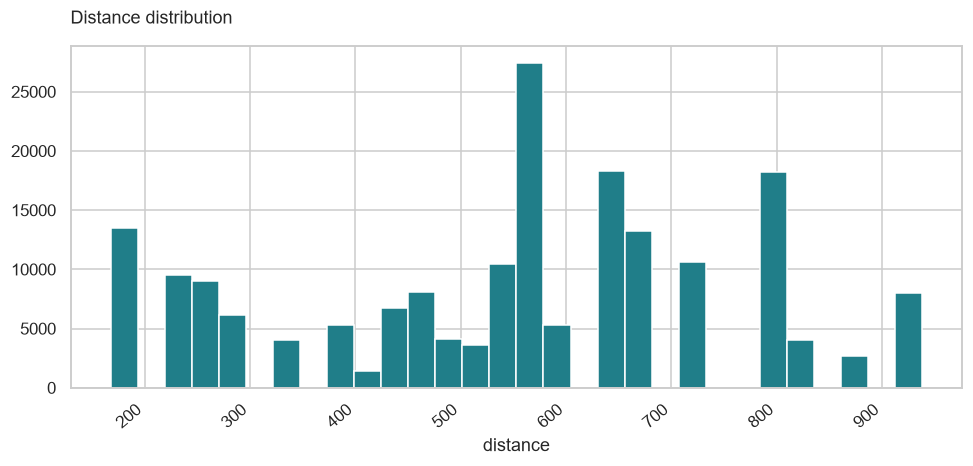

Observed insight: distance: median=562.14; 10th–90th percentile=242.21–808.85.


In [11]:
figure, observed_insight = draw_chart(TASK, 6, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 8
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

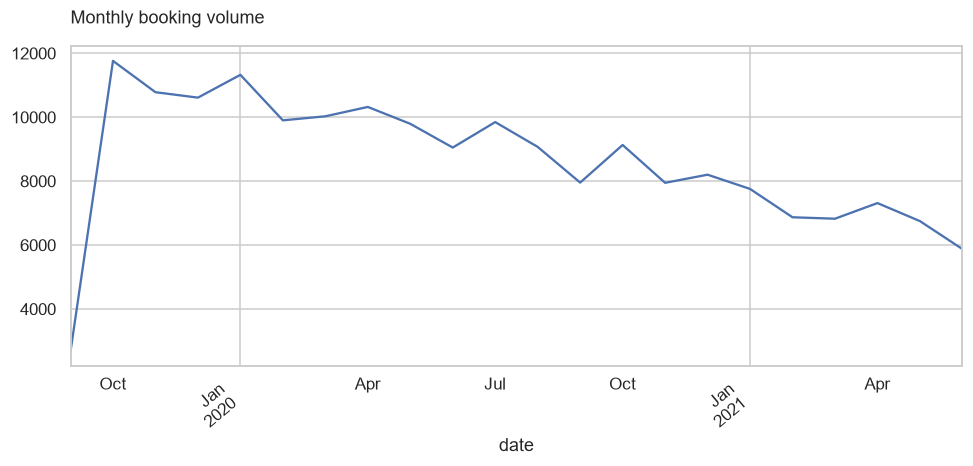

Observed insight: Monthly values range from 2670.00 to 11762.00. Partial boundary months can affect the comparison.


In [12]:
figure, observed_insight = draw_chart(TASK, 7, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 9
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

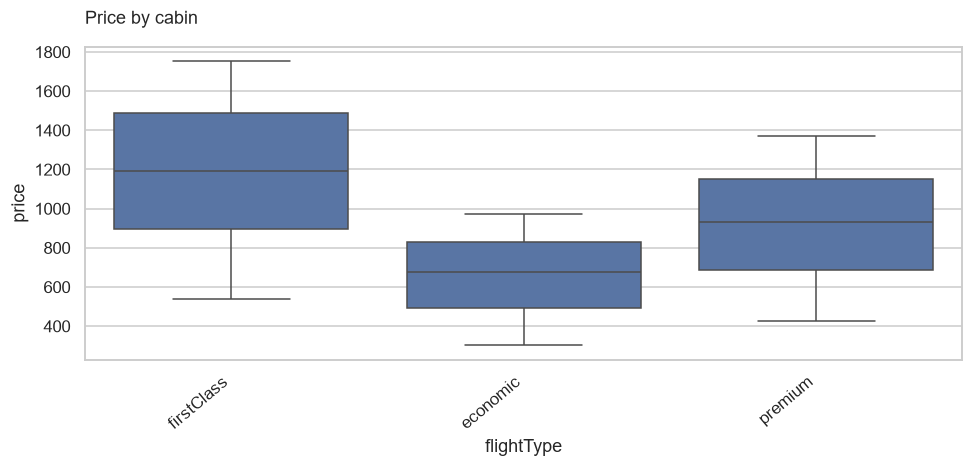

Observed insight: Median price ranges from 674.52 to 1190.94 across flightType groups. Differences do not establish causation.


In [13]:
figure, observed_insight = draw_chart(TASK, 8, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 10
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

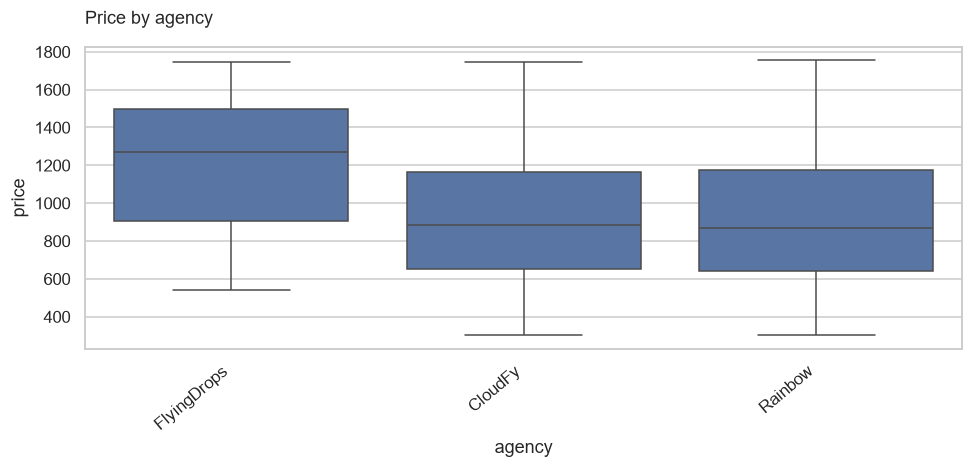

Observed insight: Median price ranges from 870.91 to 1269.73 across agency groups. Differences do not establish causation.


In [14]:
figure, observed_insight = draw_chart(TASK, 9, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 11
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

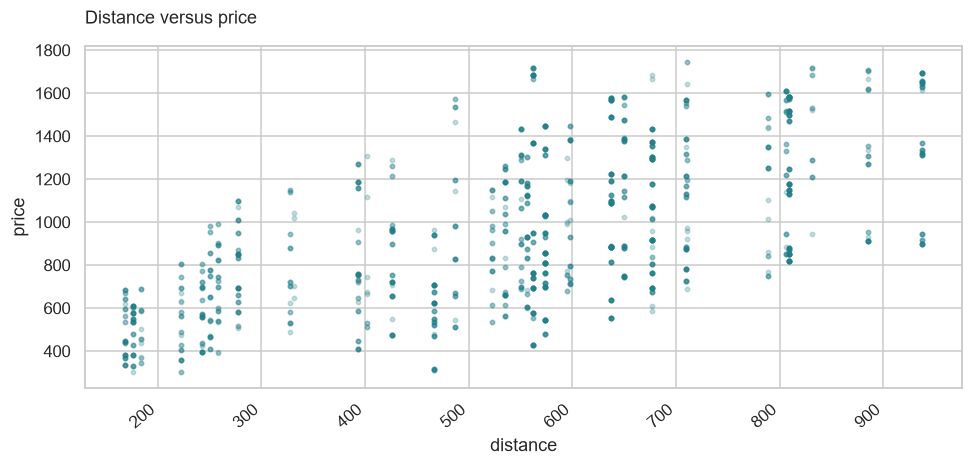

Observed insight: Training Pearson correlation between distance and price: 0.643. Plot capped at 1,500 sampled records for readability.


In [15]:
figure, observed_insight = draw_chart(TASK, 10, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 12
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

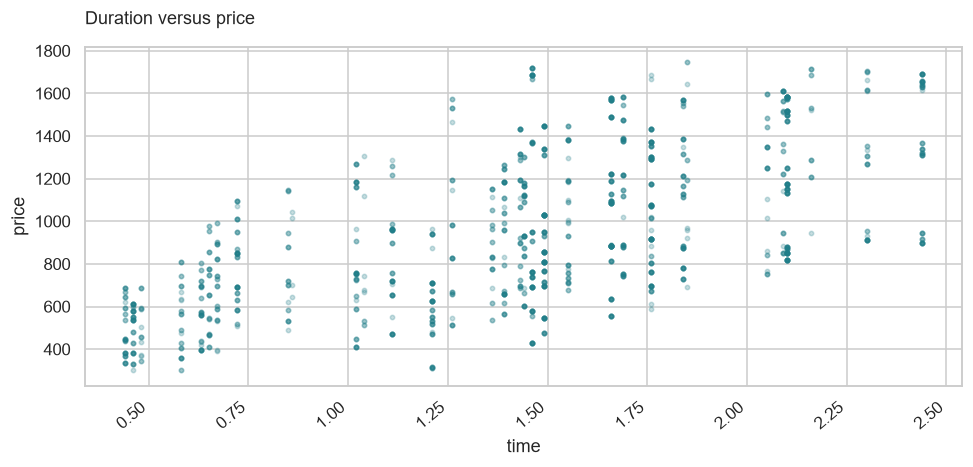

Observed insight: Training Pearson correlation between time and price: 0.643. Plot capped at 1,500 sampled records for readability.


In [16]:
figure, observed_insight = draw_chart(TASK, 11, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 13
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

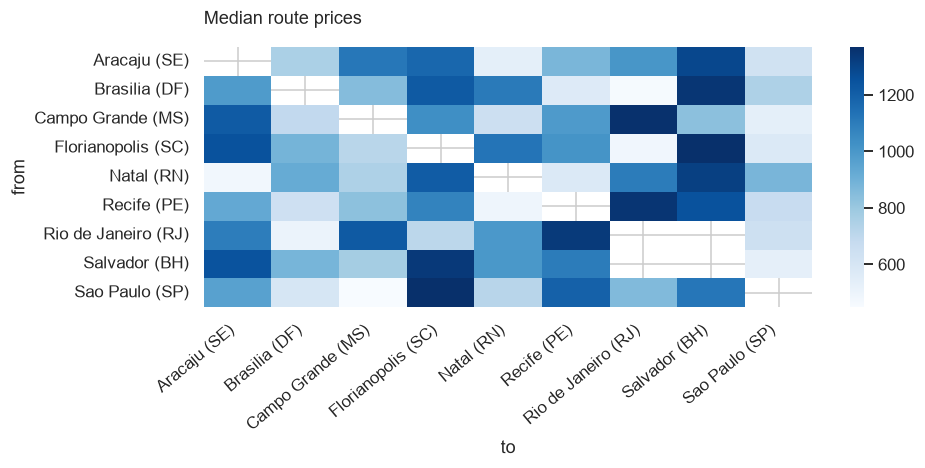

Observed insight: 70 origin/destination cells contain historical observations; blank cells are not zero fares.


In [17]:
figure, observed_insight = draw_chart(TASK, 12, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 14
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

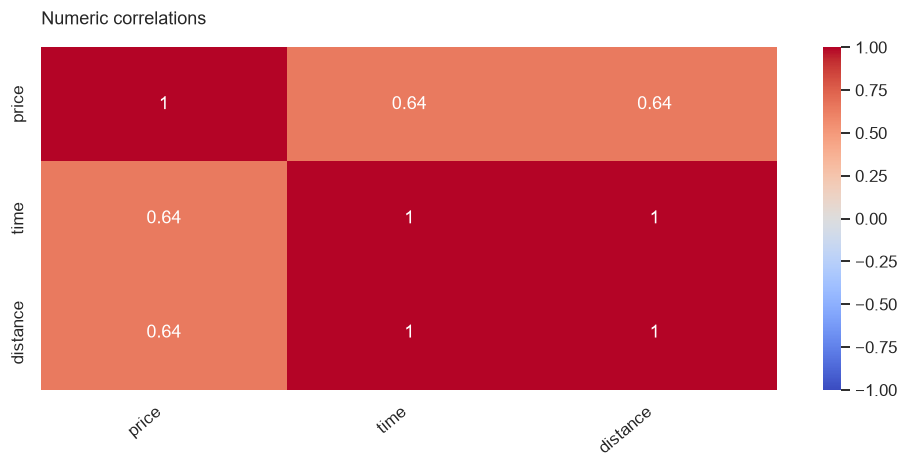

Observed insight: Correlated duration and distance can provide overlapping information; associations do not establish future pricing accuracy.


In [18]:
figure, observed_insight = draw_chart(TASK, 13, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

### Chart 15
        **Why this chart?** A distribution, group comparison or relationship plot exposes the support and variation relevant to this task. Counts and proportions help distinguish common patterns from thinly represented cases.

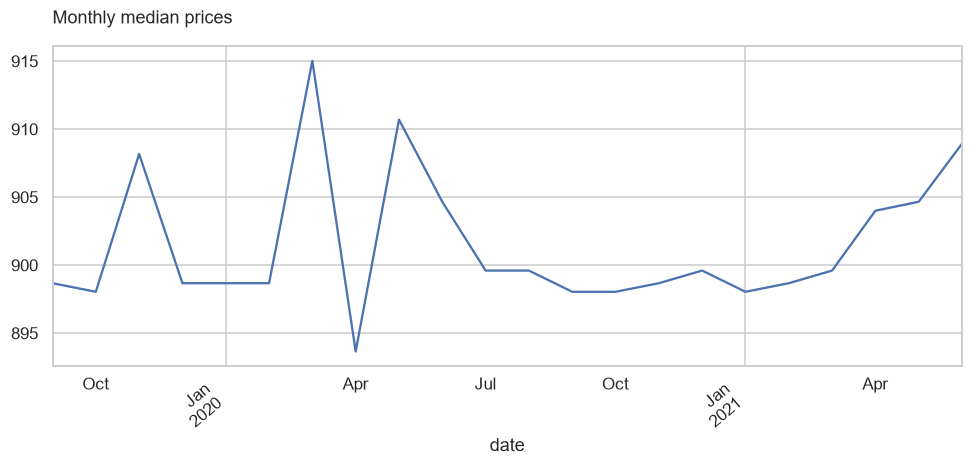

Observed insight: Monthly values range from 893.65 to 915.02. Partial boundary months can affect the comparison.


In [19]:
figure, observed_insight = draw_chart(TASK, 14, eda)
image_buffer = BytesIO()
figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(figure)
print('Observed insight:', observed_insight)

**Business implication:** Use the measured observation to guide feature checks, coverage limits and evaluation slices. It can support budgeting or catalogue exploration, but it is not proof of a causal effect or increased business revenue. Sparse groups and historical patterns can produce poor generalization; the independent holdout checks this separately.

## 5. Hypothesis Testing
    These are exploratory checks on training data only, using three comparisons and a Bonferroni significance level of 0.05/3. Statistical association does not establish practical predictive value. Flight/hotel records repeat users and trips, so the tests use one observation per user to reduce within-user dependence; remaining observational confounding limits interpretation.

In [20]:
from scipy.stats import kruskal, chi2_contingency, spearmanr
independent = eda.drop_duplicates('code' if TASK == 'classification' else 'userCode')
tests = []
if TASK == 'flights':
    for category in ['flightType', 'agency']:
        groups = [group.price.to_numpy() for _, group in independent.groupby(category)]
        statistic, p = kruskal(*groups)
        tests.append((f'H0: price distributions are equal across {category}', statistic, p))
    statistic, p = spearmanr(independent.distance, independent.price)
    tests.append(('H0: distance and price have zero rank association', statistic, p))
elif TASK == 'classification':
    statistic, p, dof, expected = chi2_contingency(pd.crosstab(independent.company, independent.gender))
    tests.append(('H0: company and source label are independent', statistic, p))
    print('Minimum expected count for company/label chi-square:', expected.min())
    statistic, p = kruskal(*[group.age.to_numpy() for _, group in independent.groupby('gender')])
    tests.append(('H0: age distributions are equal across labels', statistic, p))
    statistic, p = kruskal(*[group.age.to_numpy() for _, group in independent.groupby('company')])
    tests.append(('H0: age distributions are equal across companies', statistic, p))
else:
    statistic, p = kruskal(*[group.days.to_numpy() for _, group in independent.groupby('place')])
    tests.append(('H0: stay distributions are equal across destinations', statistic, p))
    statistic, p = spearmanr(independent.days, independent.total)
    tests.append(('H0: stay duration and total have zero rank association', statistic, p))
    statistic, p = spearmanr(independent.price, independent.days)
    tests.append(('H0: nightly price and duration have zero rank association', statistic, p))
hypothesis_results = pd.DataFrame(tests, columns=['null_hypothesis', 'statistic', 'p_value'])
hypothesis_results['decision'] = np.where(hypothesis_results.p_value < .05 / 3, 'Reject H0 (exploratory)', 'Do not reject H0')
display(hypothesis_results)

,null_hypothesis,statistic,p_value,decision
0,H0: price distributions are equal across fligh...,431.154420,2.376880e-94,Reject H0 (exploratory)
1,H0: price distributions are equal across agency,78.048220,1.127313e-17,Reject H0 (exploratory)
2,H0: distance and price have zero rank association,0.669476,2.581685e-174,Reject H0 (exploratory)


### Test selection and limitations
    Kruskal–Wallis compares group distributions without assuming normality; unequal distribution shapes can complicate a median-only interpretation. Spearman measures monotonic association. Chi-square tests categorical independence; inspect its expected counts before relying on the approximation. A small p-value is not an effect-size estimate. The hotel total is arithmetically related to days and nightly price, so that association is expected and cannot establish causality.

    ## 6. Feature Engineering and Data Pre-processing
    **Missing values:** none are silently imputed; invalid source inputs fail the contract.  
    **Outliers:** no arbitrary price truncation. Valid extremes stay in evaluation; boxplots hide fliers only for readability.  
    **Categorical encoding:** one-hot encoding is fitted inside training pipelines. The API rejects unknown flight categories.  
    **Text preprocessing:** not applicable; we exclude personal names and do not invent review text.  
    **Feature manipulation:** flight month and weekday come from the same serialized transformer during training and serving.  
    **Feature selection:** identifiers and target-derived columns are excluded. Hotel identifiers are items, not numeric scores.  
    **Scaling:** numeric flight features and age use training-fitted standardization; hotel interaction counts are normalized in the recommendation model.  
    **Dimensionality reduction:** unnecessary for the small feature space/catalogue.  
    **Splitting:** chronological partitions for event tasks and stratified user partitions for classification.  
    **Imbalance:** compare the classification baseline and balanced candidates using macro/per-label metrics, with no pre-split oversampling.

    ## 7. ML Model Implementation
    Candidate definitions are in `src/voyage/training.py`. The following call trains candidates, selects using validation metrics, refits the winner on training plus validation, evaluates it on the final test partition and logs the result to MLflow. Training is deliberately shared with the production workflow. The notebook does not maintain a second, divergent implementation.

In [21]:
# Set True for a fresh full training run. Saved execution uses the verified
# report/artifact when present to avoid repeating final-test selection.
REBUILD_MODELS = False
import json
report_path = Path('reports') / f'{TASK}.json'
if REBUILD_MODELS or not report_path.exists():
    run_training(TASK)
    promote(TASK)
report = json.loads(report_path.read_text(encoding='utf-8'))
candidates = pd.DataFrame(report['validation_candidates'])
display(candidates)
print('Selected:', report['selected'])
print('Selection gate:', report['quality_gate'])

,model,mae,rmse,r2,fit_seconds
0,median_baseline,300.838043,366.269404,-0.026486,1.017055
1,ridge,80.594529,102.457106,0.919678,0.903201
2,hist_gradient_100,12.609022,15.910483,0.998063,7.094955
3,hist_gradient_200,5.044376,6.616208,0.999665,9.927857


Selected: hist_gradient_200
Selection gate: {'passed': True, 'rule': 'Validation RMSE at least 10% below median baseline'}


### Model comparison and tuning
    Regression compares a median baseline, Ridge, and two histogram-gradient-boosting iteration budgets. Classification compares a majority baseline, balanced logistic regression and a depth-limited random forest. Recommendation compares popularity (alpha=0) with two personalization weights. This is a bounded validation search, not nested cross-validation; no claim of exhaustive tuning is made. Preprocessing is fitted on training observations for each candidate. The final test results never determine which candidate wins.

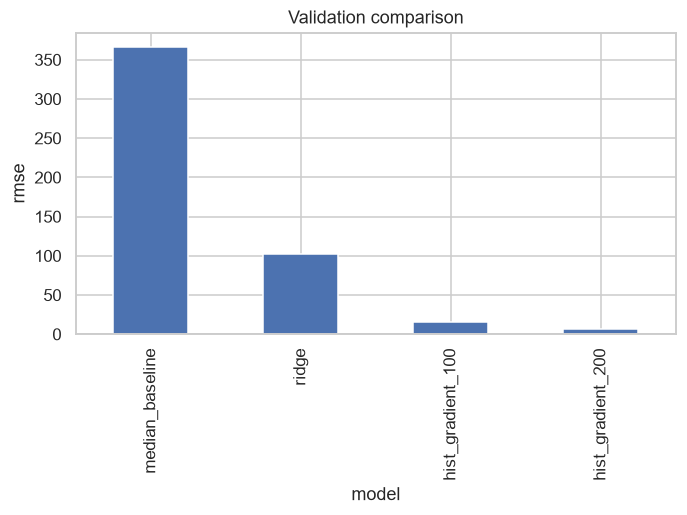

,selected_model,baseline
mae,5.749933,302.310657
rmse,7.693520,368.252820
r2,0.999550,-0.031791


,from,to,flightType,n,mae
86,Florianopolis (SC),Recife (PE),premium,358,20.924494
33,Brasilia (DF),Natal (RN),economic,117,19.720654
59,Campo Grande (MS),Natal (RN),premium,136,19.257974
188,Sao Paulo (SP),Aracaju (SE),premium,158,18.333865
0,Aracaju (SE),Brasilia (DF),economic,218,18.027944
85,Florianopolis (SC),Recife (PE),firstClass,524,16.357199
67,Campo Grande (MS),Salvador (BH),firstClass,163,15.136867
203,Sao Paulo (SP),Recife (PE),premium,124,14.594406
58,Campo Grande (MS),Natal (RN),firstClass,234,14.195112
57,Campo Grande (MS),Natal (RN),economic,148,13.715084


In [22]:
score = 'rmse' if TASK == 'flights' else ('macro_f1' if TASK == 'classification' else 'ndcg_at_3')
ax = candidates.set_index('model')[score].plot.bar(title='Validation comparison')
ax.set_ylabel(score)
plt.tight_layout()
image_buffer = BytesIO()
ax.figure.savefig(image_buffer, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image_buffer.getvalue()))
plt.close(ax.figure)
display(pd.DataFrame({'selected_model': report['test_metrics'], 'baseline': report['test_baseline']}))
if TASK == 'classification':
    display(pd.DataFrame(report['classification_report']).T)
    display(pd.DataFrame(report['confusion_matrix'], index=report['labels'], columns=report['labels']))
if TASK == 'flights':
    display(pd.DataFrame(report['error_slices']).sort_values('mae', ascending=False).head(10))

### Evaluation, business meaning and model choice
    Price errors affect budgeting. MAE expresses typical absolute error; RMSE emphasizes large mistakes; R-squared compares residual variation with target variation.

    The table shows whether personalization or a learned classifier actually improves on its baseline. A weak or negative result must stay in the report. Very high flight accuracy on this constrained historical catalogue does not imply comparable live-market accuracy. Analyze route/cabin slices and report their sample sizes. For classification, inspect each label rather than implying aggregate accuracy applies equally to everyone. Recommendation evaluation concerns held-out observed bookings, not user satisfaction.

    ### Explainability
    Use the following held-out permutation check for predictive models; it measures score changes under input permutation and may understate correlated features. For recommendations, inspect the actual popularity/history signals. Neither explanation establishes causality.

In [23]:
bundle, manifest = load_bundle(TASK)
if TASK != 'hotels':
    from sklearn.inspection import permutation_importance
    feature_names = ['company', 'age'] if TASK == 'classification' else ['from', 'to', 'flightType', 'agency', 'time', 'distance', 'date']
    sample = test.sample(min(500, len(test)), random_state=42)
    target = sample.gender if TASK == 'classification' else sample.price
    scoring = 'f1_macro' if TASK == 'classification' else 'neg_mean_absolute_error'
    explanation = permutation_importance(bundle['pipeline'], sample[feature_names], target, n_repeats=3, random_state=42, scoring=scoring)
    display(pd.DataFrame({'feature': feature_names, 'importance': explanation.importances_mean}).sort_values('importance', ascending=False))
else:
    from voyage.recommendation import recommend
    display(pd.DataFrame(recommend(bundle, user_code=0, k=3)))

,feature,importance
4,time,276.357332
2,flightType,227.967506
0,from,91.240412
1,to,73.014677
5,distance,21.242352
3,agency,20.621623
6,date,0.001182


## 8. Future Work and Deployment Artifact
    The complete pipeline or recommendation bundle is saved as joblib with a SHA-256 manifest. A separate promotion operation only approves passing candidates; failed candidates preserve the current release. The Flask app loads the exact same artifact at startup. MLflow records the experiment and bundle. Kubernetes/Jenkins deployment evidence is maintained separately and must not be inferred merely from a configuration file.

In [24]:
print('Verified version:', manifest['version'])
print('Artifact:', manifest['artifact'])
print('Checksum:', manifest['sha256'])
if TASK != 'hotels':
    sample = test.head(3)
    display(bundle['pipeline'].predict(sample[feature_names]))
else:
    display(pd.DataFrame(recommend(bundle, user_code=999999, k=3)))

Verified version: dac3c974d6ea4aeb9d8ca90bec6a0318
Artifact: releases/flights/dac3c974d6ea4aeb9d8ca90bec6a0318/model.joblib
Checksum: 9029b77f89916a47ae436fd41021f9c2bf2ae909b16418a3356ff8ca29d02f71


array([1189.75539233, 1386.39802647,  943.05179793])

# Conclusion
    This notebook connects data understanding, partition design, modeling, evaluation and a reproducible serving artifact. Read the measured comparison above before claiming any improvement. Future work includes newer independently sourced records, better documented field semantics, stronger temporal robustness checks and actual outcome feedback. Recommendation improvements require a richer catalogue. Classification remains an educational source-label benchmark with limited business relevance.

    The repository contains the API, Streamlit application, infrastructure and workflow code. The submission documentation must distinguish stages that ran successfully from stages still awaiting hosting or account setup.